# Core Genera Total Abundance (Recalled Genera)

How much of each sample's reads are in core genera (present in > 80% of seasonal plant samples, as in `core_and_rare_species_definitions_and_temporal_patterns.ipynb`). The aim is to pick a threshold for a "standard microbiome" group to compare against the rest of the samples.

Samples shown are the plates 1–5 transcriptome samples (seasonal + circadian, replicates removed), i.e. the ones that go into the DESeq2 runs at the end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
import pydeseq2.default_inference
import pydeseq2.ds
import pydeseq2.dds

core_genera_definition_threshold = 0.8
expressed_gene_reads_threshold = 2000
number_of_samples_expressed_in_threshold = 21

In [2]:
transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_tpm_normalized.csv",
    index_col=0,
)
rows_to_drop_expression_data = [
    "A2450525897_n01_undetermined",
    "A2449446903_n01_undetermined",
    "B250508004_n01_undetermined",
    "B2449500127_n01_undetermined",
]
transcriptome = transcriptome.drop(index=rows_to_drop_expression_data)
transcriptome = transcriptome.sort_index()
metadata = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Plates_1_to_5_metadata_merged_luke.csv",
    index_col=0,
)
metadata = metadata.drop(
    columns=[
        "arb.sort",
        "sample-id",
        "Ambiguous Unstranded",
        "Ambiguous Forward",
        "Multimapping",
        "Unmapped Over Mapped",
    ]
)
metadata["Date and Time"] = metadata["date"] + " " + metadata["time"]
luke_time_data_format = "%-m/%-d/%y %-H:%-M"
metadata["Date and Time"] = pd.to_datetime(
    metadata["Date and Time"], format=luke_time_data_format
)
raw_transcriptome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/plate1_5_for_norm.csv",
    index_col=0,
)

## Get plate 5 samples and remove what they replaced from the metadata to avoid duplicates
plate_5_replacements = metadata.loc[metadata["rnaprepplate"] == "LICRNA_05"]
non_plate_5_samples = metadata.loc[metadata["rnaprepplate"] != "LICRNA_05"]
replaced_samples = non_plate_5_samples.loc[
    non_plate_5_samples["sampID"].isin(plate_5_replacements["sampID"])
]
trimmed_metadata = metadata.drop(index=replaced_samples.index)
### For remaining duplicated sampIDs, drop the transcriptome with fewer total reads
double_duplicates = (
    trimmed_metadata.loc[trimmed_metadata.duplicated(subset="sampID", keep=False)]
    .sort_values(by="Total Reads")
    .drop_duplicates(subset="sampID", keep="first")
)
trimmed_metadata = trimmed_metadata.drop(index=double_duplicates.index)
### Drop failed libraries with too few reads (e.g. LIC162 has 66 total reads)
min_total_reads = 250_000
low_read_samples = trimmed_metadata.index[trimmed_metadata["Total Reads"] < min_total_reads]
trimmed_metadata = trimmed_metadata.drop(index=low_read_samples)
print(f"Dropped {len(low_read_samples)} transcriptomes with < {min_total_reads:,} total reads")
trimmed_transcriptome = transcriptome.loc[trimmed_metadata.index]
trimmed_raw_transcriptome = raw_transcriptome.loc[trimmed_metadata.index]
print("Transcriptomes after removing replicates:", len(trimmed_metadata))

Dropped 6 transcriptomes with < 250,000 total reads
Transcriptomes after removing replicates: 426


In [3]:
microbiome_abundance = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Sept_2026_recalled_genera/lic_16S_gen_rab_clean.csv"
)
plant_microbiome = microbiome_abundance.loc[microbiome_abundance["sample.type"] == "plant"]
genus_abundance_matrix = pd.pivot_table(
    plant_microbiome,
    values="Abundance",
    index="Sample",
    columns="Genus",
    aggfunc="sum",
    fill_value=0,
)
genus_abundance_matrix = (
    genus_abundance_matrix.div(genus_abundance_matrix.sum(axis=1), axis=0) * 100
)
seasonal_samples = plant_microbiome.loc[
    plant_microbiome["seascirc"] == "seasonal", "Sample"
].unique()
seasonal_prevalence = (genus_abundance_matrix.loc[seasonal_samples] > 0).mean()
core_genera = seasonal_prevalence.index[
    seasonal_prevalence > core_genera_definition_threshold
].tolist()
print(f"Core genera: {len(core_genera)}")

trimmed_metadata["core_genera_total_abund"] = trimmed_metadata["sampID"].map(
    genus_abundance_matrix[core_genera].sum(axis=1)
)
trimmed_metadata["Seasonal_or_circadian"] = np.where(
    trimmed_metadata["Experiment Type"] == "Long Term", "Seasonal", "Circadian"
)
print(
    "Transcriptomes without a microbiome profile (left out):",
    trimmed_metadata["core_genera_total_abund"].isna().sum(),
)
core_abundance = trimmed_metadata.dropna(subset=["core_genera_total_abund"])
core_abundance["core_genera_total_abund"].describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95])

Core genera: 36
Transcriptomes without a microbiome profile (left out): 2


count    424.000000
mean      91.658360
std        4.409653
min       67.332975
5%        83.905629
10%       86.194945
25%       89.589407
50%       92.619850
75%       94.730221
90%       96.251478
95%       96.872872
max       98.917527
Name: core_genera_total_abund, dtype: float64

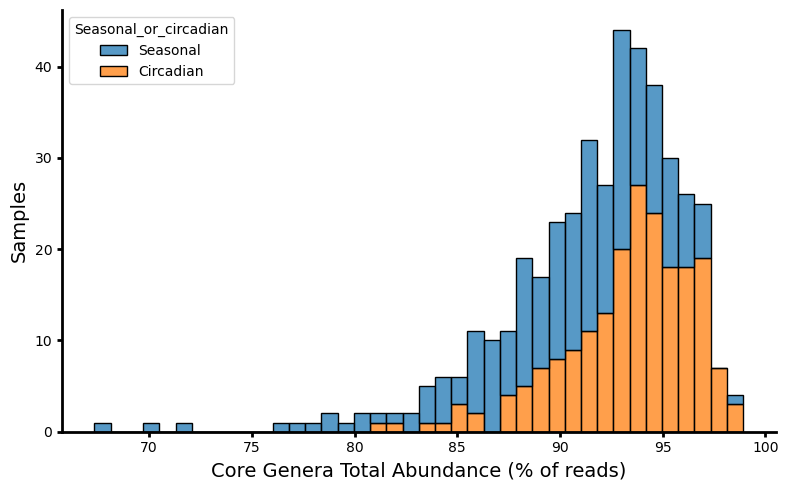

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor("white")
sns.histplot(
    data=core_abundance,
    x="core_genera_total_abund",
    hue="Seasonal_or_circadian",
    multiple="stack",
    bins=40,
    ax=ax,
)
plt.xlabel("Core Genera Total Abundance (% of reads)", fontsize=14)
plt.ylabel("Samples", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
plt.tight_layout()

Number of samples above each candidate threshold, to see how big a standard-microbiome group each would give.

,n_above,n_above_seasonal
threshold,,
80.0,415,213
81.0,412,210
82.0,409,209
83.0,408,208
84.0,400,201
85.0,394,197
86.0,384,189
87.0,370,177
88.0,355,167


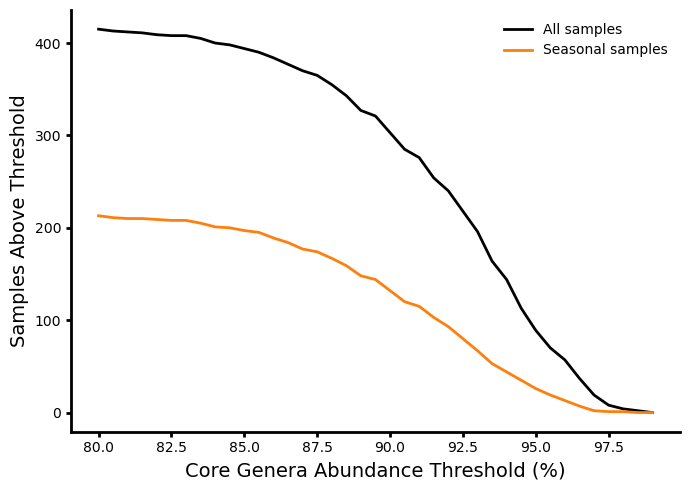

In [5]:
thresholds = np.round(np.arange(80, 99.01, 0.5), 1)
above_threshold = pd.DataFrame(
    {
        "threshold": thresholds,
        "n_above": [(core_abundance["core_genera_total_abund"] > t).sum() for t in thresholds],
        "n_above_seasonal": [
            (
                core_abundance.loc[
                    core_abundance["Seasonal_or_circadian"] == "Seasonal",
                    "core_genera_total_abund",
                ]
                > t
            ).sum()
            for t in thresholds
        ],
    }
)

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor("white")
ax.plot(above_threshold["threshold"], above_threshold["n_above"], color="black", linewidth=2, label="All samples")
ax.plot(
    above_threshold["threshold"],
    above_threshold["n_above_seasonal"],
    color="tab:orange",
    linewidth=2,
    label="Seasonal samples",
)
plt.xlabel("Core Genera Abundance Threshold (%)", fontsize=14)
plt.ylabel("Samples Above Threshold", fontsize=14)
sns.despine()
ax.spines["bottom"].set_color("black")
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_color("black")
ax.spines["left"].set_linewidth(2)
ax.tick_params(axis="both", width=2)
ax.legend(frameon=False)
plt.tight_layout()

above_threshold.loc[above_threshold["threshold"] % 1 == 0].set_index("threshold")

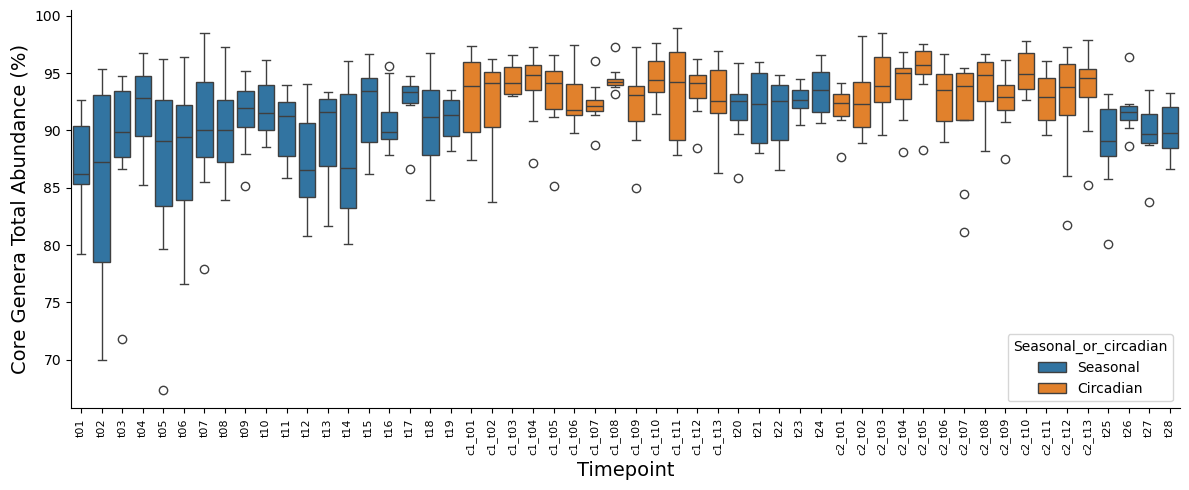

In [6]:
# Core abundance over the season, so a threshold can be judged against the time trend
fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("white")
sns.boxplot(
    data=core_abundance.sort_values("Date and Time"),
    x="timepoint",
    y="core_genera_total_abund",
    hue="Seasonal_or_circadian",
    dodge=False,
    ax=ax,
)
plt.xlabel("Timepoint", fontsize=14)
plt.ylabel("Core Genera Total Abundance (%)", fontsize=14)
plt.xticks(rotation=90, fontsize=8)
sns.despine()
plt.tight_layout()

## Comparison: core species total abundance in the old data

Old species-level table (`lic2024_16S_rab.csv`, `AbundR100` = % of reads), with the core species from `species_core_results.csv` (the old core/rare notebook). Abundance is summed directly per plant, so samples with several transcriptomes aren't double counted. The old table only contains taxa above 0.5% of reads, so its totals are not directly comparable: rare taxa below that floor are simply missing.

In [7]:
old_microbiome = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/Microbiome/lic2024_16S_rab.csv"
)
old_species_table = pd.read_csv(
    "/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/species_core_results.csv"
)
old_core_species = old_species_table.loc[old_species_table["core"] == True, "Species"].tolist()
print(f"Old core species: {len(old_core_species)}")

old_core_abund = (
    old_microbiome.loc[old_microbiome["Species"].isin(old_core_species)]
    .groupby("plantID")["AbundR100"]
    .sum()
)
old_total_abund = old_microbiome.groupby("plantID")["AbundR100"].sum()
print(f"Old table total AbundR100 per sample: median {old_total_abund.median():.1f}% (taxa < 0.5% were filtered out)")

core_abundance["old_core_species_total_abund"] = core_abundance["sampID"].map(old_core_abund)
print("Samples without an old profile:", core_abundance["old_core_species_total_abund"].isna().sum())
core_abundance[["core_genera_total_abund", "old_core_species_total_abund"]].describe()

Old core species: 10
Old table total AbundR100 per sample: median 89.2% (taxa < 0.5% were filtered out)
Samples without an old profile: 0


/var/folders/nk/6xkk9sgn1pz4ff1b36sfq3y40000gt/T/ipykernel_15663/2755187482.py:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  core_abundance["old_core_species_total_abund"] = core_abundance["sampID"].map(old_core_abund)


,core_genera_total_abund,old_core_species_total_abund
count,424.000000,424.000000
mean,91.658360,52.462500
std,4.409653,12.435864
min,67.332975,11.100000
25%,89.589407,45.250000
50%,92.619850,54.500000
75%,94.730221,61.200000
max,98.917527,78.800000


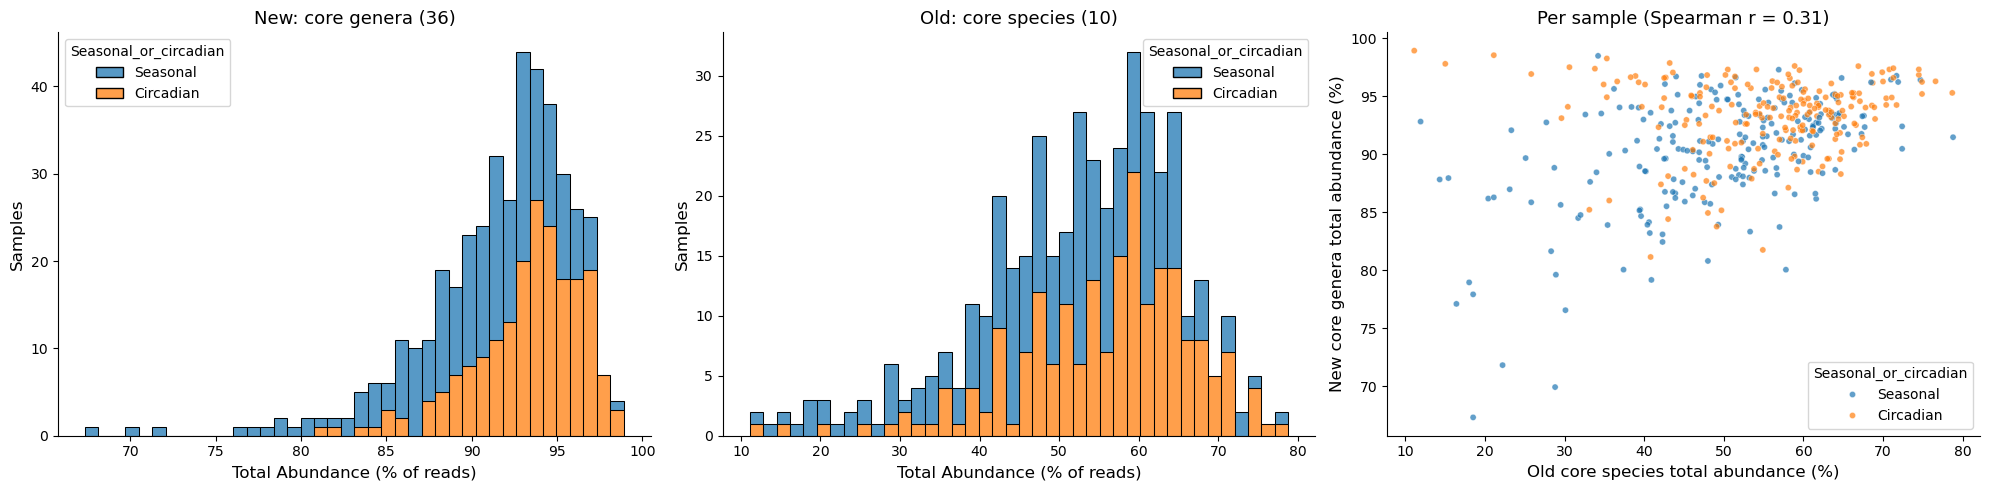

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.patch.set_facecolor("white")
for ax, (column, title) in zip(
    axes[:2],
    [
        ("core_genera_total_abund", "New: core genera (36)"),
        ("old_core_species_total_abund", f"Old: core species ({len(old_core_species)})"),
    ],
):
    sns.histplot(
        data=core_abundance,
        x=column,
        hue="Seasonal_or_circadian",
        multiple="stack",
        bins=40,
        ax=ax,
    )
    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Total Abundance (% of reads)", fontsize=12)
    ax.set_ylabel("Samples", fontsize=12)
    sns.despine(ax=ax)

sns.scatterplot(
    data=core_abundance,
    x="old_core_species_total_abund",
    y="core_genera_total_abund",
    hue="Seasonal_or_circadian",
    alpha=0.7,
    s=20,
    ax=axes[2],
)
r = core_abundance[["old_core_species_total_abund", "core_genera_total_abund"]].corr(method="spearman").iloc[0, 1]
axes[2].set_title(f"Per sample (Spearman r = {r:.2f})", fontsize=13)
axes[2].set_xlabel("Old core species total abundance (%)", fontsize=12)
axes[2].set_ylabel("New core genera total abundance (%)", fontsize=12)
sns.despine(ax=axes[2])
plt.tight_layout()

## Differential expression by core abundance

DESeq2 with the original design, `~timepoint + group`, on all transcriptome samples that have a microbiome profile (the 4 without one are left out). Each run compares one group against all other samples:

- **Standard microbiome:** core genera > 95%, > 96% and > 97% of reads.
- **Low core:** core genera < 85% of reads.

Gene filters are the same as the dysbiosis DE notebooks (> 2000 total reads, > 1 read in more than 21 samples). Full results are saved to `Generated_data/deseq_core_abundance_*.csv`.

In [9]:
inference = pydeseq2.default_inference.DefaultInference(n_cpus=6)
de_samples = core_abundance.index
de_counts = trimmed_raw_transcriptome.loc[de_samples]
de_counts = de_counts.loc[:, de_counts.sum() > expressed_gene_reads_threshold]
de_counts = de_counts.loc[:, (de_counts > 1).sum() > number_of_samples_expressed_in_threshold]
print("Samples:", len(de_samples), "| genes tested:", de_counts.shape[1])

core_groups = {
    "core > 95%": core_abundance["core_genera_total_abund"] > 95,
    "core > 96%": core_abundance["core_genera_total_abund"] > 96,
    "core > 97%": core_abundance["core_genera_total_abund"] > 97,
    "core < 85%": core_abundance["core_genera_total_abund"] < 85,
}
for name, in_group in core_groups.items():
    print(
        f"{name}: {in_group.sum()} in group "
        f"({(in_group & (core_abundance['Seasonal_or_circadian'] == 'Seasonal')).sum()} seasonal)"
    )

Samples: 424 | genes tested: 18024
core > 95%: 89 in group (26 seasonal)
core > 96%: 57 in group (13 seasonal)
core > 97%: 19 in group (2 seasonal)
core < 85%: 30 in group (25 seasonal)


In [10]:
core_de_results = {}
core_de_summaries = []
for name, in_group in core_groups.items():
    metadata = pd.DataFrame(
        {
            "timepoint": core_abundance["timepoint"],
            "group": np.where(in_group, "In", "Rest"),
        },
        index=de_samples,
    )
    with contextlib.redirect_stdout(io.StringIO()):
        dds = pydeseq2.dds.DeseqDataSet(
            counts=de_counts,
            metadata=metadata,
            design="~timepoint+group",
            refit_cooks=True,
            inference=inference,
            quiet=True,
        )
        dds.deseq2()
        stats = pydeseq2.ds.DeseqStats(
            dds, contrast=["group", "In", "Rest"], inference=inference, quiet=True
        )
        stats.summary()
    results = stats.results_df
    significant = results.loc[results["padj"] < 0.05]
    core_de_results[name] = results
    core_de_summaries.append(
        {
            "comparison": f"{name} vs rest",
            "n in group": int(in_group.sum()),
            "significant (padj < 0.05)": len(significant),
            "up in group": int((significant["log2FoldChange"] > 0).sum()),
            "down in group": int((significant["log2FoldChange"] < 0).sum()),
            "min padj": results["padj"].min(),
        }
    )
    file_name = name.replace(" ", "").replace(">", "above_").replace("<", "below_").replace("%", "pct")
    results.to_csv(
        f"/Users/michael/Data/Luke_terrace_experiment/General_data/Generated_data/deseq_core_abundance_{file_name}.csv"
    )
    print(core_de_summaries[-1])

pd.DataFrame(core_de_summaries).set_index("comparison")

{'comparison': 'core > 95% vs rest', 'n in group': 89, 'significant (padj < 0.05)': 0, 'up in group': 0, 'down in group': 0, 'min padj': np.float64(0.3918136867702265)}


{'comparison': 'core > 96% vs rest', 'n in group': 57, 'significant (padj < 0.05)': 0, 'up in group': 0, 'down in group': 0, 'min padj': np.float64(0.08975642816679459)}


{'comparison': 'core > 97% vs rest', 'n in group': 19, 'significant (padj < 0.05)': 0, 'up in group': 0, 'down in group': 0, 'min padj': np.float64(0.08087446525807636)}


{'comparison': 'core < 85% vs rest', 'n in group': 30, 'significant (padj < 0.05)': 0, 'up in group': 0, 'down in group': 0, 'min padj': np.float64(0.15528877533627136)}


,n in group,significant (padj < 0.05),up in group,down in group,min padj
comparison,,,,,
core > 95% vs rest,89,0,0,0,0.391814
core > 96% vs rest,57,0,0,0,0.089756
core > 97% vs rest,19,0,0,0,0.080874
core < 85% vs rest,30,0,0,0,0.155289


In [11]:
# Significant genes in any comparison
core_significant_genes = pd.concat(
    {
        name: results.loc[results["padj"] < 0.05, ["baseMean", "log2FoldChange", "padj"]]
        for name, results in core_de_results.items()
    },
    names=["comparison", "gene"],
)
core_significant_genes.sort_values("padj")

,,baseMean,log2FoldChange,padj
comparison,gene,,,


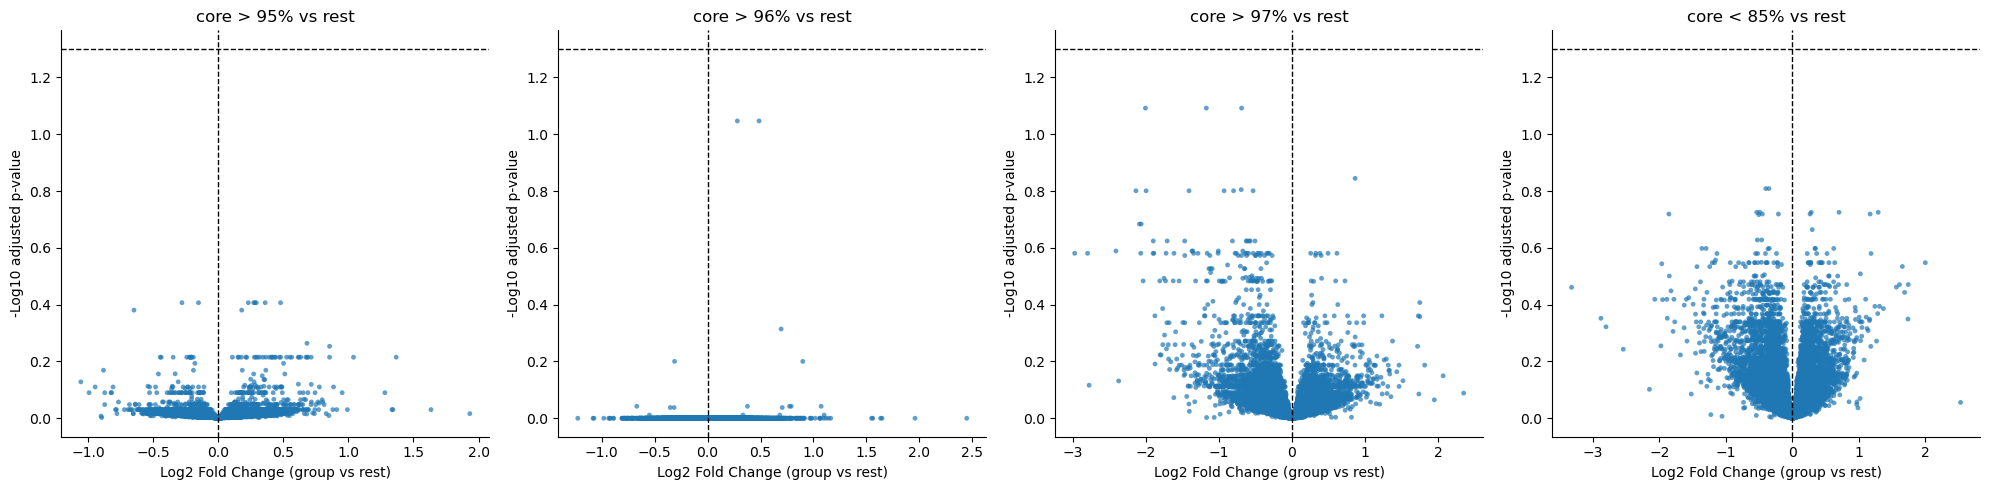

In [12]:
fig, axes = plt.subplots(1, len(core_de_results), figsize=(5 * len(core_de_results), 5))
fig.patch.set_facecolor("white")
for ax, (name, results) in zip(axes, core_de_results.items()):
    volcano_df = results[["log2FoldChange", "padj"]].replace([np.inf, -np.inf], np.nan).dropna()
    volcano_df["neg_log10_padj"] = -np.log10(volcano_df["padj"].clip(lower=1e-300))
    sns.scatterplot(
        data=volcano_df,
        x="log2FoldChange",
        y="neg_log10_padj",
        hue=volcano_df["padj"] < 0.05,
        palette={True: "tab:orange", False: "tab:blue"},
        alpha=0.7,
        s=12,
        linewidth=0,
        legend=False,
        ax=ax,
    )
    ax.axhline(-np.log10(0.05), linestyle="--", color="black", linewidth=1)
    ax.axvline(0, linestyle="--", color="black", linewidth=1)
    ax.set_title(f"{name} vs rest", fontsize=12)
    ax.set_xlabel("Log2 Fold Change (group vs rest)")
    ax.set_ylabel("-Log10 adjusted p-value")
    sns.despine(ax=ax)
plt.tight_layout()